# E-commerce customer analytics: analysis notebook

This notebook walks through the analysis behind the [live dashboard](https://mehtaaarush.github.io/ecommerce-customer-analytics/).
The cleaning and aggregation run as SQL in DuckDB (`sql/`), the modelling in Python (`retail/`), so the numbers here match the pipeline exactly.

**The data.** Every invoice line of a UK-based online gift retailer from 1 December 2009 to 9 December 2011
(UCI Online Retail II). Many of its customers are wholesalers, so orders are large and repeat buying is common.

**Outline**
1. Data and cleaning
2. How the business trades
3. Where the revenue comes from
4. Do new customers come back? (cohorts)
5. Who the customers are (RFM segmentation)
6. Who will order in the next 90 days? (repurchase model)
7. What sells together? (market basket)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from retail import basket, cohorts, config, db, kpis, repurchase, rfm
from retail.figures import _style, BASELINE, BLUE, ORANGE

%matplotlib inline
_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 50)

## 1. Data and cleaning

`db.connect()` downloads the workbook on first use (checking its SHA-256 hash), caches it as Parquet and loads it into DuckDB.
`sql/01_clean.sql` then gives every raw line exactly one status, checked in this order: exact duplicate, non-product code
(postage, fees, manual adjustments), cancellation, zero or negative quantity/price, price keying error, otherwise a sale.

In [2]:
con = db.connect()
raw_rows = con.execute("SELECT COUNT(*) FROM raw_lines").fetchone()[0]
first, last = con.execute("SELECT MIN(invoice_date), MAX(invoice_date) FROM raw_lines").fetchone()
print(f"{raw_rows:,} invoice lines from {first:%d %b %Y} to {last:%d %b %Y}")
con.execute("SELECT * FROM raw_lines LIMIT 5").df()

1,067,371 invoice lines from 01 Dec 2009 to 09 Dec 2011


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085,United Kingdom


In [3]:
funnel = kpis.funnel(con)
funnel[["label", "lines", "share", "amount", "lines_without_customer", "kept"]]

,label,lines,share,amount,lines_without_customer,kept
0,Product sales,1003329,0.940,"19,600,960.180",226754,True
1,Cancellations (netted from revenue),17914,0.017,"-716,425.970",328,True
2,Exact duplicate lines,34335,0.032,"431,716.870",7856,False
3,"Postage, fees and manual adjustments",5823,0.005,"-71,887.202",2161,False
4,Zero-price lines and stock write-offs,5961,0.006,0.000,5901,False
5,Price keying errors,9,0.000,"42,886.690",7,False


The statuses add up to the raw file, so nothing is dropped silently. Product sales are 94% of lines. Two groups would have distorted revenue
if left in: **exact duplicate lines** (the same invoice, product, quantity, price and timestamp repeated) and a handful of **price keying errors**,
sale lines priced more than 100 times the product's median price. The threshold sits in a clean gap: no sale line is priced between 75 and 100
times its median. Cancellations stay in and are netted against revenue.

In [4]:
dupes = funnel.set_index("status").loc["duplicate"]
gross = funnel.set_index("status").loc["sale", "amount"]
print(f"Duplicate lines: {dupes['lines']:,}, worth £{dupes['amount']:,.0f} ({dupes['amount'] / gross:.1%} of gross product sales)")
con.execute(
    "SELECT invoice, invoice_date, stock_code, description, quantity, price, amount "
    "FROM lines WHERE status = 'price error' ORDER BY amount DESC"
).df()

Duplicate lines: 34,335, worth £431,717 (2.2% of gross product sales)


,invoice,invoice_date,stock_code,description,quantity,price,amount
0,556444,2011-06-10 15:28:00,22502,PICNIC BASKET WICKER 60 PIECES,60,649.500,"38,970.000"
1,507637,2010-05-10 14:55:00,84016,FLAG OF ST GEORGE CAR FLAG,1,"1,157.150","1,157.150"
2,502451,2010-03-24 14:14:00,84016,FLAG OF ST GEORGE CAR FLAG,1,867.790,867.790
3,556446,2011-06-10 15:33:00,22502,PICNIC BASKET WICKER 60 PIECES,1,649.500,649.500
4,506571,2010-04-30 13:04:00,84016,FLAG OF ST GEORGE CAR FLAG,1,408.400,408.400
5,500315,2010-03-07 11:56:00,84016,FLAG OF ST GEORGE CAR FLAG,1,280.750,280.750
6,513439,2010-06-24 14:17:00,84016,FLAG OF ST GEORGE CAR FLAG,1,272.270,272.270
7,500586,2010-03-09 10:02:00,84016,FLAG OF ST GEORGE CAR FLAG,2,93.610,187.220
8,502469,2010-03-24 15:39:00,84016,FLAG OF ST GEORGE CAR FLAG,1,93.610,93.610


In [5]:
sales = funnel.set_index("status").loc["sale"]
print(f"Sale lines without a customer ID (guest checkouts): {sales['lines_without_customer'] / sales['lines']:.1%}")

Sale lines without a customer ID (guest checkouts): 22.6%


About a fifth of sale lines have no customer ID. They count toward revenue and orders but cannot enter any customer-level analysis
(cohorts, RFM, the model), which therefore describe identified accounts only.

## 2. How the business trades

The data cover two comparable twelve-month years, December to November. December 2011 has only eight trading days and is left out of comparisons.

In [6]:
monthly = kpis.monthly(con)
yoy = kpis.yoy(kpis.yearly(con, monthly))
yoy.loc[["net_revenue", "gross_sales", "orders", "aov", "customers", "repeat_rate"]]

period,year1,year2,change
net_revenue,"9,152,835.550","9,291,299.100",0.015
gross_sales,"9,393,360.360","9,593,108.900",0.021
orders,"19,736.000","18,955.000",-0.040
aov,475.951,506.099,0.063
customers,"4,239.000","4,293.000",0.013
repeat_rate,0.664,0.638,-0.025


Net revenue grew 1.5% to £9.29M on 4.0% fewer orders: the average order grew 6.3% to £506. The share of customers ordering twice or more
in the year fell 2.5 points to 63.8% (`change` is a point difference for this rate, a relative change elsewhere).

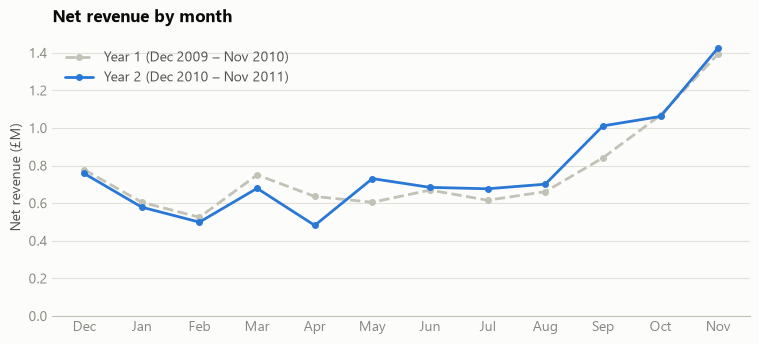

In [7]:
months = pd.date_range(config.YEAR2[0], periods=12, freq="MS")
fig, ax = plt.subplots(figsize=(9, 3.6))
for label, (start, end), color, style in [("Year 1 (Dec 2009 – Nov 2010)", config.YEAR1, BASELINE, "--"),
                                          ("Year 2 (Dec 2010 – Nov 2011)", config.YEAR2, BLUE, "-")]:
    m = monthly[(monthly["month"] >= start) & (monthly["month"] < end)]
    ax.plot(range(12), m["net_revenue"] / 1e6, style, color=color, lw=2, marker="o", ms=4, label=label)
ax.set_xticks(range(12), [d.strftime("%b") for d in months])
ax.set_ylabel("Net revenue (£M)")
ax.set_ylim(0)
ax.legend(loc="upper left")
ax.set_title("Net revenue by month")
plt.show()

In [8]:
y2 = monthly[(monthly["month"] >= config.YEAR2[0]) & (monthly["month"] < config.YEAR2[1])].set_index("month")
autumn = y2.loc["2011-09-01":"2011-11-01", "net_revenue"].sum() / y2["net_revenue"].sum()
print(f"September–November share of year-2 revenue: {autumn:.1%}")
print(f"November 2011 net revenue: £{y2.loc['2011-11-01', 'net_revenue'] / 1e6:.2f}M")

timing = kpis.weekday_hour(con)
by_hour = timing.sum(axis=0)
outside = by_hour[(by_hour.index < 8) | (by_hour.index >= 18)].sum() / by_hour.sum()
print(f"Busiest day: {timing.drop(index='Sat', errors='ignore').sum(axis=1).idxmax()}; busiest hour starts at {by_hour.idxmax()}:00")
print(f"Saturday orders in two years: {int(timing.loc['Sat'].sum()) if 'Sat' in timing.index else 0}; "
      f"orders before 08:00 or after 18:00: {outside:.1%}")

September–November share of year-2 revenue: 37.7%
November 2011 net revenue: £1.43M
Busiest day: Thu; busiest hour starts at 12:00
Saturday orders in two years: 30; orders before 08:00 or after 18:00: 2.3%


Christmas makes the year: September to November bring 38% of year-2 revenue, as wholesale buyers stock up well before December.
Orders follow office hours (peak at noon, Thursday the busiest day) and the business barely trades on Saturdays.

## 3. Where the revenue comes from

In [9]:
mix = yoy.loc[["revenue_returning", "revenue_new", "revenue_guest"], "year2"] / yoy.loc["net_revenue", "year2"]
print("Year-2 revenue by customer type:")
print(mix.rename(lambda k: k.replace("revenue_", "")).map("{:.1%}".format).to_string())

countries = kpis.countries(con)
countries.assign(revenue_share=countries["revenue_share"].map("{:.1%}".format))

Year-2 revenue by customer type:
returning    77.6%
new           7.3%
guest        15.1%


,country,net_revenue,orders,customers,revenue_share
0,United Kingdom,"16,126,041.090",36175,5334,85.4%
1,EIRE,"603,116.610",581,3,3.2%
2,Netherlands,"546,095.430",216,22,2.9%
3,Germany,"374,573.510",753,107,2.0%
4,France,"293,431.200",598,93,1.6%
5,Australia,"166,282.150",89,15,0.9%
6,Switzerland,"92,918.060",85,22,0.5%
7,Spain,"84,811.560",144,38,0.4%
8,Other (35 countries),"597,264.600",866,230,3.2%


In [10]:
products = kpis.products(con)
p = kpis.pareto(products)
print(f"{p['products_for_80']:,} of {p['products']:,} products ({p['share_for_80']:.0%}) earn 80% of net revenue")
products.head(5)[["stock_code", "description", "net_revenue"]]

1,039 of 4,723 products (22%) earn 80% of net revenue


,stock_code,description,net_revenue
0,22423,REGENCY CAKESTAND 3 TIER,"314,045.020"
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"251,781.630"
2,85099B,JUMBO BAG RED RETROSPOT,"180,512.160"
3,47566,PARTY BUNTING,"147,079.730"
4,84879,ASSORTED COLOUR BIRD ORNAMENT,"128,550.420"


Returning customers carry the business (78% of year-2 revenue against 7% from customers in their first month and 15% from guest checkouts).
The year-1 split is not shown: the data begin in December 2009, so every customer would look new in year 1. The UK brings 85% of revenue,
and revenue is concentrated in a long-tail way: 22% of products earn 80% of it.

## 4. Do new customers come back?

Customers are grouped by the month of their first order and followed through November 2011. The December 2009 cohort is dropped because it
mixes genuinely new customers with everyone already buying when the data begin. Averages are weighted by cohort size and use only cohorts old
enough to have reached each month.

In [11]:
mats = cohorts.matrices(cohorts.cohort_activity(con))
retention, sizes = mats["retention"], mats["sizes"]
avg_retention = cohorts.average_curve(retention, sizes)
avg_value = cohorts.average_curve(mats["value"], sizes)
print(f"{len(sizes)} monthly cohorts, {sizes.sum():,} new customers")
(retention.iloc[:6, :8] * 100).round(1).rename(index=lambda c: c.strftime("%b %Y"))

23 monthly cohorts, 4,873 new customers


months_since,0,1,2,3,4,5,6,7
cohort,,,,,,,,
Jan 2010,100.000,21.500,32.100,31.500,27.200,31.000,26.900,23.400
Feb 2010,100.000,23.500,22.700,29.300,24.500,19.700,19.200,28.800
Mar 2010,100.000,19.000,23.100,24.300,23.100,20.400,24.700,30.600
Apr 2010,100.000,19.000,19.000,16.000,18.400,22.100,27.600,26.500
May 2010,100.000,15.700,16.900,17.600,17.600,25.500,21.200,12.500
Jun 2010,100.000,17.600,18.700,20.600,23.200,28.500,12.700,9.000


In [12]:
curves = pd.DataFrame({"share_ordering": avg_retention, "revenue_per_customer_to_date": avg_value})
curves.loc[[0, 1, 3, 6, 9, 10, 11, 12]]

,share_ordering,revenue_per_customer_to_date
months_since,,
0,1.000,443.581
1,0.210,532.717
3,0.211,721.726
6,0.184,978.719
9,0.150,"1,242.803"
10,0.135,"1,313.824"
11,0.140,"1,380.243"
12,0.184,"1,513.496"


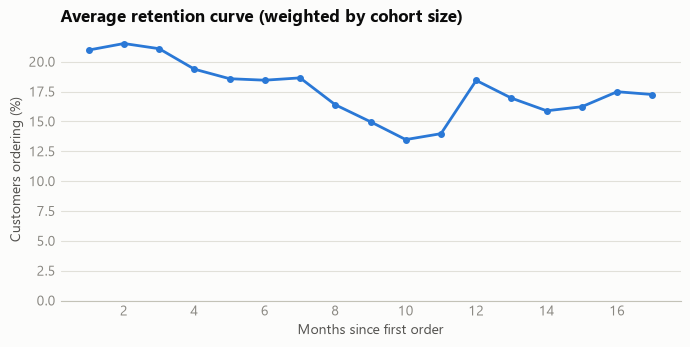

December 2010 cohort, month 1: 9% (average 21%)


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.4))
r = avg_retention.drop(0)
ax.plot(r.index, r * 100, color=BLUE, lw=2, marker="o", ms=4)
ax.set_xlabel("Months since first order")
ax.set_ylabel("Customers ordering (%)")
ax.set_ylim(0)
ax.set_title("Average retention curve (weighted by cohort size)")
plt.show()
print(f"December 2010 cohort, month 1: {retention.loc['2010-12-01', 1]:.0%} (average {avg_retention[1]:.0%})")

About one new customer in five orders again in the following month, and 18–22% are active in each of months 1–7. Activity sags to 13.5%
by month 10 and rebounds to 18.4% at month 12, when the season that brought them in comes round again. A new customer is worth £444 in their
first month and £1,380 over their first twelve (3.1×). Customers acquired in December, at the end of the season, rarely come back in January.

## 5. Who the customers are: RFM segmentation

Every identified customer is scored on recency, frequency and monetary value as of 10 December 2011 (the day after the last invoice).
Recency and monetary scores are quintiles; frequency uses fixed bands because a quarter of customers ordered once. An 11-segment map of
the recency × frequency grid assigns the segment.

In [14]:
scored = rfm.score(rfm.customers(con))
summary = rfm.summary(scored)
print(f"{len(scored):,} customers")
summary[["segment", "customers", "customer_share", "revenue_share", "median_recency", "median_frequency", "median_monetary"]]

5,852 customers


,segment,customers,customer_share,revenue_share,median_recency,median_frequency,median_monetary
0,Champions,801,0.137,0.522,9.000,12.000,"4,007.930"
1,Loyal,1053,0.180,0.272,53.000,8.000,"2,692.020"
2,Potential loyalists,714,0.122,0.042,24.000,3.000,739.120
3,New customers,73,0.012,0.002,12.000,1.000,246.300
4,Promising,164,0.028,0.003,38.000,1.000,227.015
5,Need attention,283,0.048,0.020,101.000,3.000,966.670
6,About to sleep,423,0.072,0.014,96.000,1.000,361.220
7,Can't lose them,58,0.010,0.028,308.000,13.000,"3,899.045"
8,At risk,652,0.111,0.056,368.000,4.000,"1,047.165"
9,Hibernating,679,0.116,0.018,314.000,1.000,307.530


In [15]:
seg = summary.set_index("segment")
top = seg.loc[["Champions", "Loyal"]]
quiet = seg.loc[["At risk", "Can't lose them"]]
print(f"Champions + Loyal: {top['customers'].sum():,} customers ({top['customer_share'].sum():.0%}), {top['revenue_share'].sum():.0%} of revenue")
print(f"At risk + Can't lose them: {quiet['customers'].sum():,} customers ({quiet['customer_share'].sum():.0%}), "
      f"£{quiet['revenue'].sum() / 1e6:.2f}M of past revenue")

Champions + Loyal: 1,854 customers (32%), 79% of revenue
At risk + Can't lose them: 710 customers (12%), £1.37M of past revenue


Do the segments mean anything? To check, the same scoring is applied as of 11 September 2011 and compared with who actually ordered
in the following 90 days.

In [16]:
validation = rfm.validate(con)
validation[["segment", "customers", "repurchase_rate", "revenue_per_customer", "future_revenue_share"]]

,segment,customers,repurchase_rate,revenue_per_customer,future_revenue_share
0,Champions,721,0.831,"2,048.492",0.538
1,Loyal,857,0.681,736.574,0.230
2,Potential loyalists,612,0.516,386.898,0.086
3,New customers,104,0.558,333.147,0.013
4,Promising,135,0.385,215.746,0.011
5,Need attention,256,0.438,202.513,0.019
6,About to sleep,468,0.250,115.793,0.020
7,Can't lose them,34,0.294,191.084,0.002
8,At risk,546,0.313,176.004,0.035
9,Hibernating,654,0.251,127.423,0.030


The segments order behaviour as intended: 83% of Champions ordered in the next 90 days against 12% of Lost customers.

## 6. Who will order in the next 90 days?

A propensity model turns the segments into a ranking. Each row is one customer at one cutoff date: 15 features from their history
before the cutoff, labelled 1 if they ordered in the 90 days after it. The design is strictly out of time:

* four quarterly training cutoffs; models are fitted on the first three and chosen by PR AUC on the fourth (validation);
* the chosen model is refitted on all four and scored **once** on the held-out quarter from 11 September 2011;
* the baseline is the RFM score itself, with each score's repurchase rate in the training data as its probability.

In [17]:
model = repurchase.evaluate(con)
print(f"{model['n_train']:,} training customer-quarters, {model['n_test']:,} test customers; selected: {model['selected']}")
model["windows"]

17,223 training customer-quarters, 5,256 test customers; selected: logit


,cutoff,label_end,customers,base_rate,role
0,2010-09-16,2010-12-14,3388,0.574,train
1,2010-12-15,2011-03-14,4295,0.299,train
2,2011-03-15,2011-06-12,4588,0.355,train
3,2011-06-13,2011-09-10,4952,0.321,validation
4,2011-09-11,2011-12-09,5256,0.436,test


In [18]:
cols = ["name", "roc_auc", "pr_auc", "brier", "top_decile_lift", "buyers_captured", "revenue_captured", "mean_predicted", "base_rate"]
print("Validation quarter (model choice):")
display(model["selection"][cols])
print("Held-out test quarter:")
display(model["metrics"][cols])
b = model["bootstrap"]
print(f"Paired bootstrap ({config.N_BOOT} resamples), selected model minus RFM score:")
print(f"  ROC AUC: 95% CI {b['roc_auc']['low']:+.3f} to {b['roc_auc']['high']:+.3f}")
print(f"  revenue reached by the top 20%: 95% CI {b['revenue_captured']['low'] * 100:+.1f} to {b['revenue_captured']['high'] * 100:+.1f} pp")

Validation quarter (model choice):


,name,roc_auc,pr_auc,brier,top_decile_lift,buyers_captured,revenue_captured,mean_predicted,base_rate
0,RFM score (baseline),0.807,0.671,0.165,2.684,0.453,0.754,0.409,0.321
1,Logistic regression,0.825,0.730,0.152,2.759,0.473,0.762,0.357,0.321
2,Gradient boosting,0.813,0.722,0.152,2.803,0.477,0.772,0.330,0.321


Held-out test quarter:


,name,roc_auc,pr_auc,brier,top_decile_lift,buyers_captured,revenue_captured,mean_predicted,base_rate
0,RFM score (baseline),0.783,0.731,0.188,2.082,0.383,0.699,0.389,0.436
1,Logistic regression,0.802,0.778,0.186,2.152,0.388,0.697,0.350,0.436
2,Gradient boosting,0.797,0.773,0.193,2.130,0.384,0.691,0.330,0.436


Paired bootstrap (300 resamples), selected model minus RFM score:
  ROC AUC: 95% CI +0.015 to +0.023
  revenue reached by the top 20%: 95% CI -0.8 to +0.9 pp


Logistic regression wins the validation quarter and holds up on the test quarter: ROC AUC 0.802 against 0.783 for the RFM score, a gap whose
95% interval (+0.015 to +0.023) excludes zero. Gradient boosting is close behind and not worth its extra complexity here.

The honest caveat: at a fixed campaign size the gain is small. Contacting the top 20% reaches about 39% of next-quarter buyers and 70% of
next-quarter revenue with either ranking (the revenue difference is not significant). The model's value is a finer ranking across the
whole list (higher ROC and PR AUC), not a different top 20%.

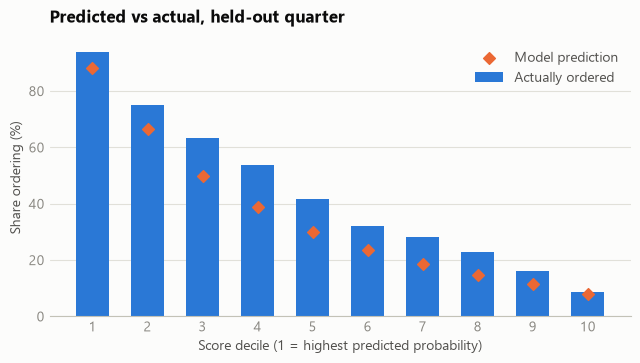

,decile,customers,predicted,observed,revenue_share
0,1,526,0.883,0.937,0.565
1,2,526,0.664,0.751,0.133
2,3,525,0.498,0.634,0.106
3,4,526,0.387,0.536,0.063
4,5,525,0.299,0.415,0.044
5,6,526,0.237,0.321,0.030
6,7,526,0.187,0.281,0.025
7,8,525,0.146,0.230,0.019
8,9,526,0.114,0.160,0.010
9,10,525,0.081,0.088,0.005


In [19]:
deciles = model["deciles"]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(deciles["decile"], deciles["observed"] * 100, color=BLUE, width=0.6, label="Actually ordered")
ax.scatter(deciles["decile"], deciles["predicted"] * 100, color=ORANGE, marker="D", s=36, zorder=3, label="Model prediction")
ax.set_xticks(deciles["decile"])
ax.set_xlabel("Score decile (1 = highest predicted probability)")
ax.set_ylabel("Share ordering (%)")
ax.legend(loc="upper right")
ax.set_title("Predicted vs actual, held-out quarter")
plt.show()
deciles[["decile", "customers", "predicted", "observed", "revenue_share"]]

The top decile ordered at 94% and brought 56% of the quarter's revenue. The model ranks well but under-predicts every decile: the test quarter
is the Christmas peak, when 44% ordered against 35% predicted on average. Recalibrate on the latest quarter before reading the scores as forecasts.

In [20]:
model["importance"][["label", "importance", "std"]].head(8)

,label,importance,std
0,Months with an order,0.205,0.004
1,Orders in the last 90 days,0.058,0.004
2,Orders 91–180 days ago,0.022,0.002
3,Days since first order,0.021,0.001
4,Products per order,0.014,0.001
5,Orders in the same quarter last year,0.009,0.001
6,Distinct products bought,0.004,0.001
7,Orders to date,0.004,0.001


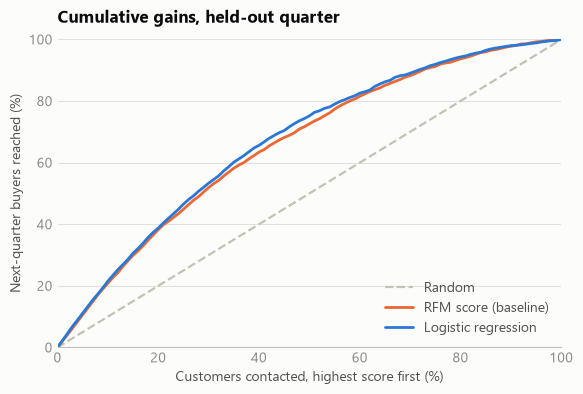

In [21]:
g, sel = model["gains"], model["selected"]
names = model["metrics"].set_index("key")["name"]
fig, ax = plt.subplots(figsize=(6.5, 4))
frac = g[sel]["fraction"] * 100
ax.plot(frac, frac, color=BASELINE, ls="--", lw=1.6, label="Random")
ax.plot(frac, g["rfm"]["buyers"] * 100, color=ORANGE, lw=2, label=names["rfm"])
ax.plot(frac, g[sel]["buyers"] * 100, color=BLUE, lw=2, label=names[sel])
ax.set_xlabel("Customers contacted, highest score first (%)")
ax.set_ylabel("Next-quarter buyers reached (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc="lower right")
ax.set_title("Cumulative gains, held-out quarter")
plt.show()

Permutation importance on the test quarter: shuffling *months with an order* costs the most average precision by far, followed by orders in the
last 90 days. Breadth of engagement over time matters more than any single recent order, and days since the last order adds almost nothing once
recent order counts are known.

## 7. What sells together?

Among the 400 most-ordered products, every pair bought together in at least 60 orders becomes two rules (A → B and B → A) with
support = P(A and B), confidence = P(B | A) and lift = confidence / P(B).

In [22]:
rules = basket.rules(basket.pairs(con))
sizes_b = basket.basket_sizes(con)
print(f"{len(rules) // 2:,} product pairs ({len(rules):,} rules)")
print(f"Median order: {sizes_b['median_products']:.0f} distinct products (mean {sizes_b['mean_products']:.0f}); "
      f"{sizes_b['multi_product_share']:.0%} of orders hold more than one")

names = products.set_index("stock_code")["description"]
strong = rules[rules["support"] >= 0.01]
pair = np.where(strong["antecedent"] < strong["consequent"], strong["antecedent"] + "|" + strong["consequent"],
                strong["consequent"] + "|" + strong["antecedent"])
top = (strong.assign(pair=pair).sort_values(["lift", "confidence"], ascending=False).drop_duplicates("pair").head(10)
       .assign(product_a=lambda d: d["antecedent"].map(names), product_b=lambda d: d["consequent"].map(names)))
top[["product_a", "product_b", "together", "support", "confidence", "lift"]]

44,361 product pairs (88,722 rules)
Median order: 15 distinct products (mean 25); 92% of orders hold more than one


,product_a,product_b,together,support,confidence,lift
0,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,557,0.014,0.751,42.186
2,SET/10 PINK POLKADOT PARTY CANDLES,SET/10 BLUE SPOTTY PARTY CANDLES,488,0.012,0.605,37.981
4,FELTCRAFT PRINCESS CHARLOTTE DOLL,FELTCRAFT PRINCESS LOLA DOLL,401,0.010,0.585,35.746
6,PINK POLKADOT CUP,BLUE POLKADOT CUP,521,0.013,0.694,35.641
8,BLUE POLKADOT BOWL,PINK POLKADOT BOWL,460,0.012,0.664,34.505
11,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,552,0.014,0.719,34.129
13,"KEY FOB , BACK DOOR","KEY FOB , SHED",481,0.012,0.699,33.078
14,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,546,0.014,0.720,31.169
16,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,651,0.016,0.772,31.005
18,FELTCRAFT CUSHION BUTTERFLY,FELTCRAFT CUSHION RABBIT,491,0.012,0.626,30.660


The strongest rules pair a product with its twin in another colour or design: 75% of orders with Poppy's Playhouse kitchen also include
the bedroom, 42 times more often than chance. With 15 products in the median order, buyers already build large mixed baskets, so a
"goes with" list per product (the dashboard's product picker) is a cheap cross-sell.

## Conclusions

* **Clean before counting.** Duplicate lines alone were worth 2.2% of gross sales; leaving them in would overstate revenue and order counts.
* **Revenue held up on fewer, larger orders**, and the year is made in September to November. Stock and campaigns should follow that calendar.
* **Retention is steady but low** (about one in five new customers active in each of their first seven months), while returning
  customers bring 78% of revenue.
  Converting first-time buyers is the biggest lever.
* **A third of customers bring four-fifths of revenue.** 710 At-risk and Can't-lose customers with £1.37M of past revenue are the win-back list.
* **The repurchase model beats the RFM rule out of time**, but by a small margin at campaign level; recalibrate before using its probabilities as forecasts.
* **Matching sets and colourways sell together**: show the twin product on the product page and in the basket.